# CartPole Failure Prediction: Exploratory Data Analysis

**Course:** Machine Learning - Semester 2026-III
**Workshop 1:** Data Preparation & Supervised Learning Baselines

## Overview
This notebook characterises the CartPole dataset before any model is trained.
The task is a **binary classification**: predict whether an episode is about to fail
(`label = 1` during the last 5 steps of every failed episode).

## Learning Objectives
- Verify the integrity of the dataset and describe its structure
- Analyse the target distribution and the class imbalance
- Compute feature statistics and detect quality issues
- Explore feature relationships and what separates the two classes
- Justify the preprocessing decisions (episode-level split, scaling, features)

## 1. Setup

We fix the random seed and import the project modules (`src/dataset.py`, `src/features.py`)
so that the notebook uses exactly the same code as the baselines.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make the `src/` package importable from the notebook
sys.path.insert(0, str(Path.cwd().parent / "src"))
from dataset import (SEED, RAW_CSV, STATE_COLS, RAW_FEATURE_COLS, TARGET_COL,
                     EPISODE_COL, load_raw, sha256_of_file, set_global_seed,
                     get_or_create_splits, subset)
from features import build_features, THETA_LIMIT, X_LIMIT

set_global_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Seed:", SEED)

Seed: 42


## 2. Dataset Integrity and Structure

First we confirm the file is the expected one (SHA256) and inspect its shape and types.

In [2]:
EXPECTED_SHA = "ec067d5dcc498f2b5c5486d24f290283431ef3a0db0a4952cfde84f07e4f53f8"
digest = sha256_of_file(RAW_CSV)
print("=" * 60)
print(f"SHA256 matches expected: {digest == EXPECTED_SHA}")
print(f"Size on disk: {RAW_CSV.stat().st_size / 1024**2:.2f} MB")

df = load_raw()
print(f"Shape: {df.shape} | Episodes: {df[EPISODE_COL].nunique()}")
print("=" * 60)
df.head()

SHA256 matches expected: True
Size on disk: 1.99 MB
Shape: (35874, 8) | Episodes: 400


,episode,t,x,x_dot,theta,theta_dot,action,label
0,0,0,0.015230,-0.045622,-0.047997,0.033921,0,0
1,0,1,0.014317,-0.240024,-0.047319,0.311083,1,0
2,0,2,0.009517,-0.044261,-0.041097,0.003860,0,0
3,0,3,0.008632,-0.238771,-0.041020,0.283299,1,0
4,0,4,0.003856,-0.043088,-0.035354,-0.022034,0,0


In [3]:
print(df.dtypes.to_string())
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

episode        int64
t              int64
x            float64
x_dot        float64
theta        float64
theta_dot    float64
action         int64
label          int64

Missing values: 0
Duplicate rows: 0


## 3. Target Distribution

The workshop requires class counts and the imbalance ratio. A strong imbalance means
**accuracy is not a valid metric** (always predicting "safe" gives ~94.5 %).

class 0:  33904 (94.51%)
class 1:   1970 (5.49%)
Imbalance ratio: 17.2 : 1
Accuracy of a trivial 'always 0' classifier: 94.509%


/tmp/ipykernel_208/3337084975.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, palette=["#4C72B0", "#C44E52"])


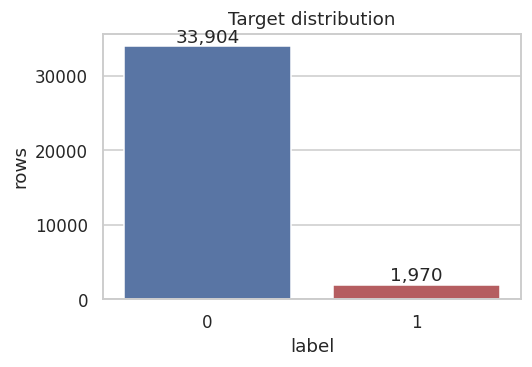

In [4]:
counts = df[TARGET_COL].value_counts().sort_index()
ratio = counts.max() / counts.min()
print("=" * 60)
for cls, n in counts.items():
    print(f"class {cls}: {n:6d} ({100 * n / len(df):.2f}%)")
print(f"Imbalance ratio: {ratio:.1f} : 1")
print(f"Accuracy of a trivial 'always 0' classifier: {counts[0] / len(df):.3%}")
print("=" * 60)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, palette=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_xlabel("label"); ax.set_ylabel("rows"); ax.set_title("Target distribution")
plt.tight_layout(); plt.show()

## 4. Episode Structure

`label = 1` only appears in the **last 5 steps** of episodes that end in failure.
Episodes that reach the 500-step limit have no positive rows. We verify this and look at
the episode-length distribution, which is very skewed.

Max steps-to-end among positives: 4
Min steps-to-end among negatives (failed episodes only): 5
Episodes with no positives (reached 500 steps): 6

Episode length summary:
count    400.0
mean      89.7
std      113.5
min        8.0
25%       18.0
50%       34.5
75%      117.2
max      500.0


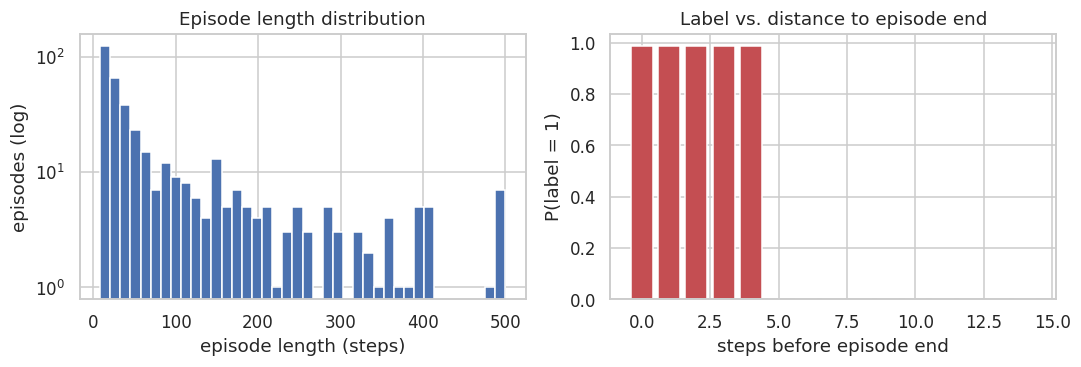

In [5]:
df["steps_to_end"] = df.groupby(EPISODE_COL)["t"].transform("max") - df["t"]
lengths = df.groupby(EPISODE_COL).size()
pos_per_ep = df.groupby(EPISODE_COL)[TARGET_COL].sum()

print("=" * 60)
print("Max steps-to-end among positives:", int(df.loc[df.label == 1, "steps_to_end"].max()))
failed = pos_per_ep[pos_per_ep > 0].index
print("Min steps-to-end among negatives (failed episodes only):",
      int(df.loc[(df.label == 0) & df[EPISODE_COL].isin(failed), "steps_to_end"].min()))
print("Episodes with no positives (reached 500 steps):", int((pos_per_ep == 0).sum()))
print("\nEpisode length summary:")
print(lengths.describe().round(1).to_string())
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(lengths, bins=40, color="#4C72B0"); axes[0].set_yscale("log")
axes[0].set_xlabel("episode length (steps)"); axes[0].set_ylabel("episodes (log)")
axes[0].set_title("Episode length distribution")
rate = df.groupby("steps_to_end")[TARGET_COL].mean().head(15)
axes[1].bar(rate.index, rate.values, color="#C44E52")
axes[1].set_xlabel("steps before episode end"); axes[1].set_ylabel("P(label = 1)")
axes[1].set_title("Label vs. distance to episode end")
plt.tight_layout(); plt.show()

## 5. Feature Statistics and Data Quality

Summary statistics of the raw numerical features, plus a check for outliers using the IQR rule.
Note that every recorded state lies **inside** the CartPole failure limits
(|theta| < 0.2095 rad, |x| < 2.4 m): the terminal state that triggers the failure is not stored.

In [6]:
print(df[RAW_FEATURE_COLS].agg(["min", "max", "mean", "std"]).T.round(4).to_string())

print("\nIQR outlier percentage per feature:")
for col in STATE_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).mean()
    print(f"  {col:>10}: {100 * out:5.2f}%")
print(f"\nMax |theta| = {df.theta.abs().max():.4f} (limit {THETA_LIMIT}) | Max |x| = {df.x.abs().max():.4f} (limit {X_LIMIT})")
print(f"Usable samples: {100 * (1 - df.isna().any(axis=1).mean()):.1f}% (no missing / corrupted rows)")

              min     max    mean     std
x         -2.3993  2.3993  0.0222  0.7140
x_dot     -2.5948  2.7101  0.0121  0.6189
theta     -0.2094  0.2094 -0.0008  0.0742
theta_dot -2.9550  2.6379 -0.0085  0.4708
action     0.0000  1.0000  0.5017  0.5000

IQR outlier percentage per feature:
           x: 26.36%
       x_dot:  2.97%
       theta:  3.83%
   theta_dot:  4.25%

Max |theta| = 0.2094 (limit 0.2095) | Max |x| = 2.3993 (limit 2.4)
Usable samples: 100.0% (no missing / corrupted rows)


## 6. Feature Distributions by Class

Histograms of each state variable split by label. If the classes overlap heavily in the raw
variables, a linear model will struggle.

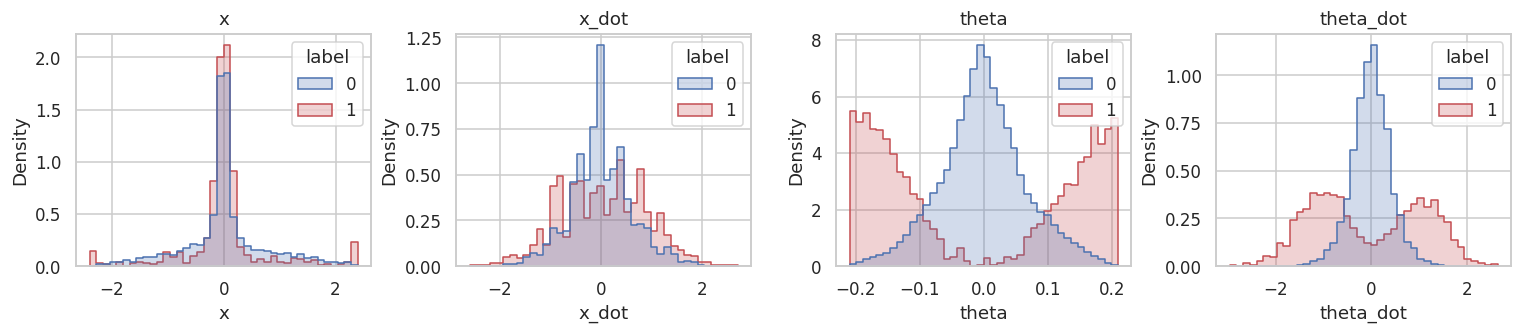

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, col in zip(axes, STATE_COLS):
    sns.histplot(data=df, x=col, hue=TARGET_COL, stat="density", common_norm=False,
                 bins=40, element="step", ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 7. Feature Relationships

Correlation matrix of the raw features and the target. Correlations with `label` are weak, which
already suggests the problem is **non-linear**.

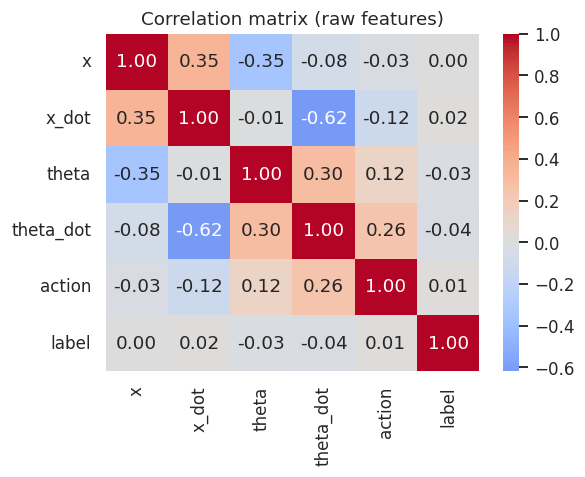

In [8]:
corr = df[RAW_FEATURE_COLS + [TARGET_COL]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (raw features)")
plt.tight_layout(); plt.show()

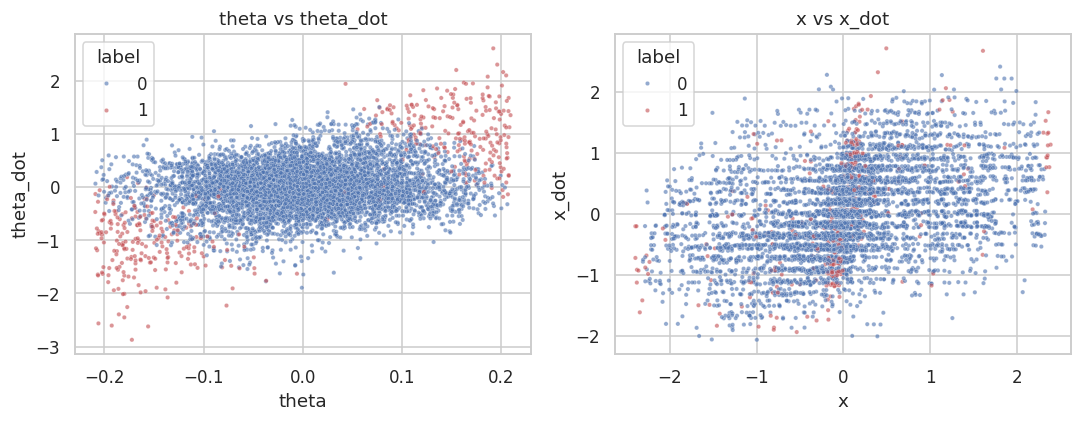

In [9]:
# Phase-space view: where do the positive samples live?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sample = df.sample(8000, random_state=SEED)
for ax, (a, b) in zip(axes, [("theta", "theta_dot"), ("x", "x_dot")]):
    sns.scatterplot(data=sample, x=a, y=b, hue=TARGET_COL, s=8, alpha=0.6,
                    palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(f"{a} vs {b}")
plt.tight_layout(); plt.show()

## 8. Engineered Features

Domain knowledge: an episode fails when |theta| > 0.2095 rad or |x| > 2.4 m. Therefore the
**distance to those limits** and the **speed of approach** should be predictive.
We build the 16 features (past-only, see `src/features.py`) and compare them across classes.

Feature matrix: (35874, 16) | NaN: 0


/tmp/ipykernel_208/1368095891.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="label", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
/tmp/ipykernel_208/1368095891.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="label", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])


/tmp/ipykernel_208/1368095891.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="label", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])


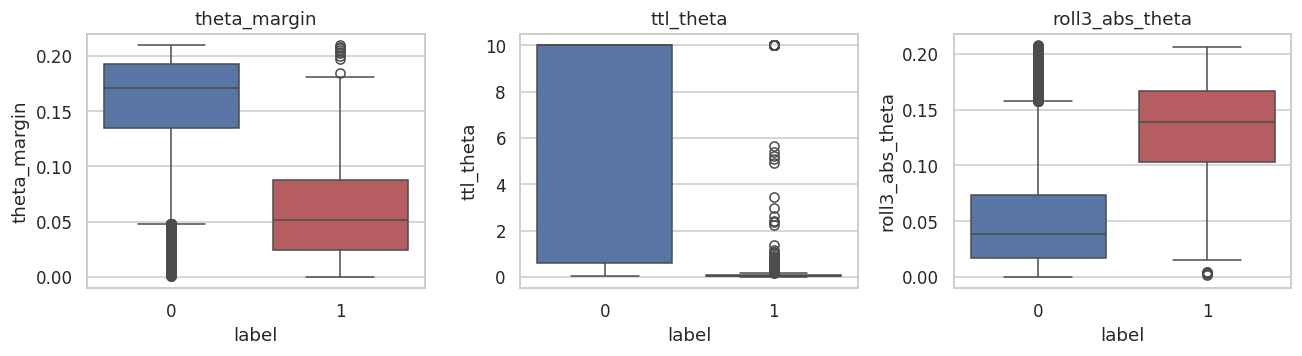

roll3_abs_theta_dot    0.561
theta_margin          -0.472
abs_theta              0.472
roll3_abs_theta        0.411
ttl_theta             -0.269
ttl_x                 -0.138
theta_dot             -0.036
d_theta               -0.034


In [10]:
X = build_features(df)
print("Feature matrix:", X.shape, "| NaN:", int(X.isna().sum().sum()))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axes, ["theta_margin", "ttl_theta", "roll3_abs_theta"]):
    plot_df = pd.DataFrame({col: X[col], "label": df[TARGET_COL]})
    sns.boxplot(data=plot_df, x="label", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
plt.tight_layout(); plt.show()

# Which engineered features correlate most with the target?
print((X.assign(label=df[TARGET_COL]).corr()["label"].drop("label")
       .sort_values(key=np.abs, ascending=False).head(8).round(3)).to_string())

## 9. Train / Validation / Test Split

Because consecutive rows of an episode are almost identical, the split is done **by episode**
(70/15/15), stratified by length quartile, and saved in `data/splits.json`.

In [11]:
splits = get_or_create_splits(df)
print("=" * 60)
for name, eps in splits.items():
    part = subset(df, eps)
    print(f"{name:>5}: {len(eps):3d} episodes | {len(part):6d} rows | "
          f"positives {part[TARGET_COL].mean():.2%}")
overlap = set(splits["train"]) & set(splits["val"]) | set(splits["train"]) & set(splits["test"]) | set(splits["val"]) & set(splits["test"])
print("Episode overlap between partitions:", len(overlap))
print("=" * 60)

train: 279 episodes |  24782 rows | positives 5.57%
  val:  61 episodes |   5762 rows | positives 5.21%
 test:  60 episodes |   5330 rows | positives 5.44%
Episode overlap between partitions: 0


## 10. Key Findings

| Finding | Consequence for the pipeline |
|---|---|
| 17.2 : 1 imbalance (5.49 % positives) | Do not rely on accuracy; use precision, recall, F1, ROC-AUC and PR-AUC; class weights |
| Rows of one episode are highly correlated | Split **by episode**; never by row |
| Very skewed episode lengths (8 to 500 steps) | Stratify the split by episode length |
| Weak linear correlation with the label | Expect a linear baseline to struggle on raw features; engineer features |
| States always inside the failure limits | Distance-to-limit and approach-speed features are meaningful |
| No missing values or duplicates | No imputation required |